# Notebook 09 — The classical cone follower

Companion to [Lecture 9](../09_perception_driven_racing.md) (§7–§8). The planner that drives SAURCON, taken apart:
the Delaunay centreline (§7.1, Figure 9.1), why a gate-width window alone cannot reject boundary chords (problem
9.5), pure-pursuit lookahead in closed loop (§7.2, equation 9.2), the speed limit that falls as the visible path
shortens (§7.3, equation 9.3), the follower driving a lap in MuJoCo, and the real failing frame from the feature
warehouse (§7.5) with the old and new crossing tests side by side.

All code calls `saurcon_plan.cone_follower` itself, so what you see is what runs on the car.

In [1]:
import sys, math, os
from pathlib import Path
import numpy as np, matplotlib.pyplot as plt
from scipy.spatial import Delaunay
WS = Path('../../..').resolve()
sys.path.insert(0, str(WS / 'src' / 'saurcon_plan')); sys.path.insert(0, str(WS / 'src' / 'saurcon_rl'))
os.environ.setdefault('MUJOCO_GL', 'egl')
from saurcon_plan.cone_follower import ConeFollower
from saurcon_plan.vehicle import WHEELBASE, STEER_MAX
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'grid.color': '#e4e3df',
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE, AQUA, MAGENTA, RED, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#e87ba4', '#e34948', '#8d8b86'

def bend_cones(R=4.0, w=2.2, s=0.65, miss=0.15, seed=4, start=-1.0, length=7.0):
    # Cones of a left bend of centreline radius R starting at the car, in {B}; a fraction `miss` dropped.
    a = np.arange(start, length, s); th = np.clip(a, 0, None) / R
    c = np.column_stack([np.where(a < 0, a, R*np.sin(th)), np.where(a < 0, 0, R - R*np.cos(th))])
    n = np.column_stack([-np.sin(th), np.cos(th)])
    rng = np.random.default_rng(seed)
    L, Rr = c + w/2*n, c - w/2*n
    kl, kr = (np.hypot(*L.T) < 6.0) & (rng.random(len(L)) > miss), (np.hypot(*Rr.T) < 6.5) & (rng.random(len(Rr)) > miss)
    pts = np.vstack([L[kl], Rr[kr]]) + rng.normal(0, 0.03, (kl.sum() + kr.sum(), 2))
    return pts, np.array([1]*kl.sum() + [-1]*kr.sum())
print('wheelbase', WHEELBASE, 'm; steering limit', STEER_MAX, 'rad')

wheelbase 0.254 m; steering limit 0.786 rad


## 1. Centreline points from a Delaunay triangulation (§7.1)

Triangulate the remembered cones; keep the edges whose length lies in the gate window $[1.95, 2.75]$ m; their
midpoints are centreline candidates. Colour each edge by whether it joins the two sides (a gate or diagonal) or two
cones of the same side (a *chord*).

{'outside window': 30, 'crossing (kept)': 22, 'same-side chord in window': 1}
path 19 points, 6.36 m; command v = 4.29 m/s, steering = 3.9 deg


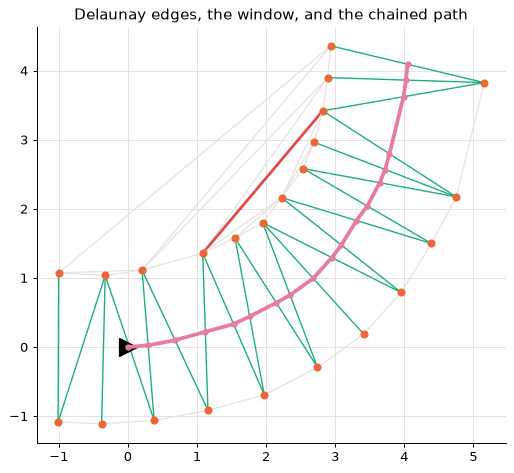

In [2]:
cones, side = bend_cones()
f = ConeFollower(); v_cmd, steer = f.act(cones, v=3.0)
tri = Delaunay(cones); E = set()
for a, b, c in tri.simplices: E |= {tuple(sorted(e)) for e in ((a, b), (b, c), (a, c))}
counts = {'outside window': 0, 'crossing (kept)': 0, 'same-side chord in window': 0}
fig, ax = plt.subplots(figsize=(7.5, 6))
for i, j in E:
    d = math.dist(cones[i], cones[j]); inw = f.min_gate <= d <= f.max_gate
    if inw and side[i] == side[j]: ax.plot(*zip(cones[i], cones[j]), color=RED, lw=2.2); counts['same-side chord in window'] += 1
    elif inw: ax.plot(*zip(cones[i], cones[j]), color=AQUA, lw=1.1); counts['crossing (kept)'] += 1
    else: ax.plot(*zip(cones[i], cones[j]), color='#e4e3df', lw=1); counts['outside window'] += 1
ax.scatter(*cones.T, s=30, color=ORANGE, zorder=3); ax.plot(*f.path.T, '-o', color=MAGENTA, lw=3, ms=4, zorder=4)
ax.plot(0, 0, '>', ms=14, color='k'); ax.set_aspect('equal'); ax.set_title('Delaunay edges, the window, and the chained path')
plt.show()
print(counts); print(f'path {len(f.path)} points, {np.sum(np.hypot(*np.diff(f.path, axis=0).T)):.2f} m; '
                    f'command v = {v_cmd:.2f} m/s, steering = {math.degrees(steer):.1f} deg')

## 2. When does a same-side chord fall inside the window? (problem 9.5)

On a straight with gate width $w$ and along-track spacing $s$, Delaunay-candidate edges have lengths $w$ (gates),
$\sqrt{w^2+(ks)^2}$ (diagonals) and $ks$ (chords along one side, when $k-1$ cones between them were missed).

In [3]:
w, lo, hi = 2.2, 1.95, 2.75
for s in (0.65, 1.17):
    rows = [('gate', w)] + [(f'diagonal k={k}', math.hypot(w, k*s)) for k in (1, 2, 3)] + [(f'chord k={k}', k*s) for k in (1, 2, 3, 4)]
    print(f'spacing s = {s} m:')
    for name, d in rows:
        print(f'   {name:13s} {d:5.2f} m  {"IN window" if lo <= d <= hi else ""}')

spacing s = 0.65 m:
   gate           2.20 m  IN window
   diagonal k=1   2.29 m  IN window
   diagonal k=2   2.56 m  IN window
   diagonal k=3   2.94 m  
   chord k=1      0.65 m  
   chord k=2      1.30 m  
   chord k=3      1.95 m  IN window
   chord k=4      2.60 m  IN window
spacing s = 1.17 m:
   gate           2.20 m  IN window
   diagonal k=1   2.49 m  IN window
   diagonal k=2   3.21 m  
   diagonal k=3   4.14 m  
   chord k=1      1.17 m  
   chord k=2      2.34 m  IN window
   chord k=3      3.51 m  
   chord k=4      4.68 m  


Both the racetrack ($s = 1.17$ m: chord $k=2$ is 2.34 m) and the feature warehouse ($s = 0.65$ m: chord $k=3$ is
1.95 m, $k=4$ is 2.60 m) put chords in the window. The window alone cannot reject them; the crossing and clearance
tests must.

## 3. Pure-pursuit lookahead in closed loop (§7.2)

Track a known path, the racetrack centreline, with (9.2) on the kinematic bicycle (1.2) including a 0.15 s steering
lag and a 50 ms delay, at 3 m/s. Small lookahead tracks tightly but oscillates; large lookahead is smooth but cuts
the bends.

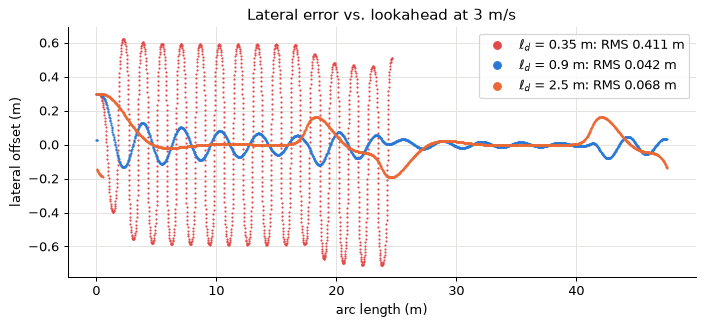

In [4]:
from saurcon_plan.track import Track
tr = Track.from_world(WS / 'src/middle_earth/worlds/racetrack.world')
def run(ld, v=3.0, T=16.0, dt=0.01, tau=0.15, delay=0.05):
    x, y, psi, d = tr.xy[0, 0], tr.xy[0, 1] + 0.3, tr.heading[0], 0.0
    i, buf, out = 0, [0.0] * int(delay / dt), []
    for k in range(int(T / dt)):
        i = tr.project(x, y, hint=i)
        j = int(np.searchsorted(tr.s, (tr.s[i] + ld) % tr.length)) % len(tr.xy)
        dx, dy = tr.xy[j] - (x, y); c, s_ = math.cos(psi), math.sin(psi)
        lx, ly = c*dx + s_*dy, -s_*dx + c*dy
        alpha = math.atan2(ly, lx); cmd = float(np.clip(math.atan2(2*WHEELBASE*math.sin(alpha), max(math.hypot(lx, ly), 0.3)), -STEER_MAX, STEER_MAX))
        buf.append(cmd); d += (buf.pop(0) - d) * dt / tau
        x += v*math.cos(psi)*dt; y += v*math.sin(psi)*dt; psi += v*math.tan(d)/WHEELBASE*dt
        e, _ = tr.frenet(x, y, psi, i); out.append((tr.s[i], e))
    return np.array(out)
fig, ax = plt.subplots(figsize=(9, 3.6))
for ld, col in ((0.35, RED), (0.9, BLUE), (2.5, ORANGE)):
    r = run(ld); ax.plot(r[:, 0], r[:, 1], '.', ms=1.5, color=col, label=f'$\\ell_d$ = {ld} m: RMS {np.sqrt(np.mean(r[200:, 1]**2)):.3f} m')
ax.set_xlabel('arc length (m)'); ax.set_ylabel('lateral offset (m)'); ax.legend(markerscale=8); ax.set_title('Lateral error vs. lookahead at 3 m/s')
plt.show()

With $\ell_d = 0.35$ m the loop is unstable: the steering lag and delay add phase, the oscillation saturates at
about ±0.6 m and the car loses the path within half a lap. With 2.5 m it is smooth but cuts each bend by ~0.15 m. The
follower uses $\ell_d = 0.7 + 0.3v$ (≤ 2.2 m), close to the middle curve at racing speed (problem N9.2 adds the
pose prediction it also uses).

## 4. Speed falls as the visible path shortens (§7.3, equation 9.3)

The third term of (9.3), *stop within the path you can see*, makes the commanded speed a function of how much of the
track is visible. Truncate the cone set to a shrinking range and record the follower's command.

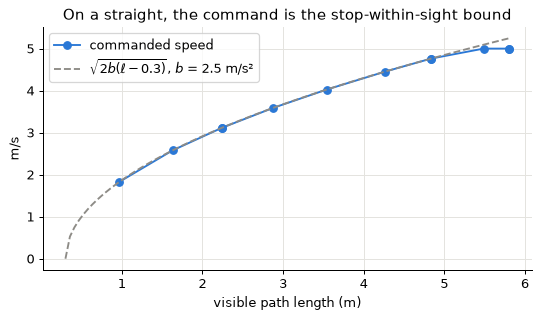

In [5]:
cones_s, _ = bend_cones(R=1e6, miss=0.0, length=9.0)          # a straight
rows = []
for rmax in np.arange(1.5, 7.01, 0.5):
    keep = np.hypot(*cones_s.T) < rmax
    f = ConeFollower(); v, _ = f.act(cones_s[keep], v=4.0)
    L = float(np.sum(np.hypot(*np.diff(f.path, axis=0).T))) if len(f.path) > 1 else 0.0
    rows.append((rmax, L, v))
rows = np.array(rows)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(rows[:, 1], rows[:, 2], 'o-', color=BLUE, label='commanded speed')
Ls = np.linspace(0.3, rows[:, 1].max(), 100); ax.plot(Ls, np.sqrt(2*2.5*np.maximum(Ls - 0.3, 0)), '--', color=GREY, label=r'$\sqrt{2b(\ell-0.3)}$, $b$ = 2.5 m/s²')
ax.set_xlabel('visible path length (m)'); ax.set_ylabel('m/s'); ax.legend(); ax.set_title('On a straight, the command is the stop-within-sight bound')
plt.show()

## 5. The follower driving a lap in MuJoCo

The same object drives the MuJoCo car from the simulated detector (as the RL policies are trained) with its 5 s cone
memory. The racetrack, from the race start, one lap.

laps 1, crashed False, lap times [12.45] s; offset std 0.078 m; fallback on 1% of steps


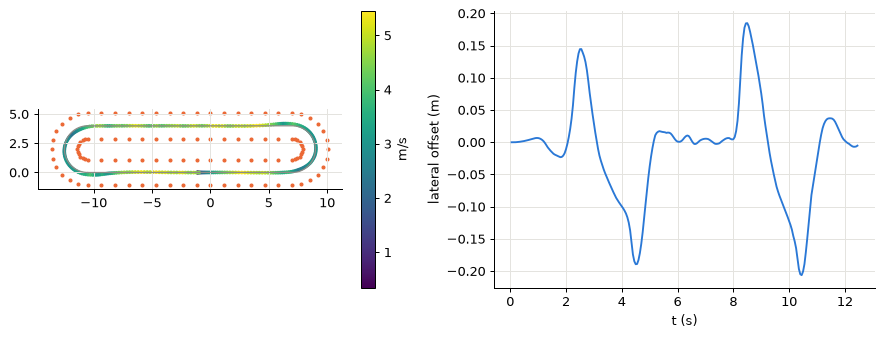

In [6]:
from saurcon_rl.cone_env import MujocoConeEnv
from saurcon_rl.env import load_tracks
from saurcon_rl.train import race_start_s
env = MujocoConeEnv(load_tracks(), randomize=False, seed=0, max_time=60)
env.reset(options={'track': 0, 'start_s': race_start_s(env.tracks[0])})
f = ConeFollower(); env.memory.horizon = f.memory_s
log = []
while True:
    rel, _ = env.memory.relative(env.x, env.y, env.yaw, env.t)
    _, _, term, trunc, info = env.step(f.action(rel, env.v, env.state[4]))
    e, _ = env.track.frenet(env.x, env.y, env.yaw, env.i); log.append((env.t, env.x, env.y, env.v, e, f.fallback))
    if term or trunc or info['laps'] >= 1: break
log = np.array(log)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(*env.track.xy.T, color=GREY, lw=1); axs[0].scatter(*env.track.cones.T, s=5, color=ORANGE)
sc = axs[0].scatter(log[:, 1], log[:, 2], c=log[:, 3], s=4, cmap='viridis'); plt.colorbar(sc, ax=axs[0], label='m/s'); axs[0].set_aspect('equal')
axs[1].plot(log[:, 0], log[:, 4], color=BLUE); axs[1].set_xlabel('t (s)'); axs[1].set_ylabel('lateral offset (m)')
plt.show()
print(f"laps {info['laps']}, crashed {term}, lap times {[round(t, 2) for t in env.lap_times]} s; "
      f"offset std {log[:, 4].std():.3f} m; fallback on {100*log[:, 5].mean():.0f}% of steps")

## 6. The real failing frame (§7.5)

`BEND_ENTRY` is the follower's cone memory at the moment the car left the feature-warehouse track: entering a left
bend, only the outer boundary visible ahead. For every Delaunay edge in the window, compare the **old** crossing
test (edge within 50° of perpendicular to the direction *to its midpoint*) with the **new** one (perpendicular to the
*path heading*, here the car's heading, plus 0.6 m clearance from every cone), for the edges the first chaining step
considers (midpoints 0.15–2.5 m ahead).

accepted by the old test only: edge [-0.15 -1.19] - [ 1.8 -0.5], length 2.07 m, midpoint [ 0.82 -0.84]


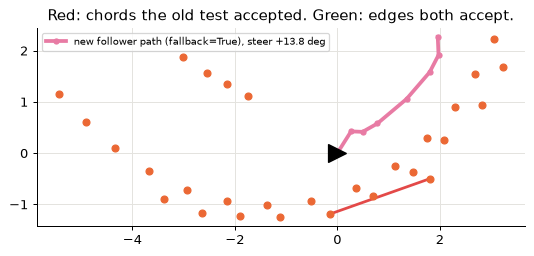

In [7]:
sys.path.insert(0, str(WS / 'src' / 'saurcon_plan' / 'test'))
from test_cone_follower import BEND_ENTRY as C
tri = Delaunay(C); E = set()
for a, b, c in tri.simplices: E |= {tuple(sorted(e)) for e in ((a, b), (b, c), (a, c))}
cos50 = math.cos(math.radians(50))
fig, ax = plt.subplots(figsize=(7, 6)); ax.scatter(*C.T, s=30, color=ORANGE, zorder=3)
for i, j in E:
    d = math.dist(C[i], C[j])
    if not 1.95 <= d <= 2.75: continue
    m = (C[i] + C[j]) / 2; u = (C[j] - C[i]) / d; r = np.hypot(*m)
    if m[0] <= 0.15 or r >= 2.5: continue          # the chain only looks 0.15-2.5 m ahead
    old_ok = abs(u @ (m / r)) <= cos50
    new_ok = abs(u @ (1.0, 0.0)) <= cos50 and np.hypot(*(C - m).T).min() >= 0.6
    col = AQUA if new_ok else (RED if old_ok else GREY)
    ax.plot(*zip(C[i], C[j]), color=col, lw=2.2 if col == RED else 1.2)
    if old_ok and not new_ok: print(f'accepted by the old test only: edge {C[i]} - {C[j]}, length {d:.2f} m, midpoint {m.round(2)}')
f = ConeFollower(latency=0.05); v, st = f.act(C, v=2.2, yaw_rate=0.54)
ax.plot(*f.path.T, '-o', color=MAGENTA, lw=3, ms=4, label=f'new follower path (fallback={f.fallback}), steer {math.degrees(st):+.1f} deg')
ax.plot(0, 0, '>', ms=14, color='k'); ax.set_aspect('equal'); ax.legend(loc='upper left', fontsize=8)
ax.set_title('Red: chords the old test accepted. Green: edges both accept.')
plt.show()

The red chord runs along the outer boundary beside the car. Seen from the car, its midpoint lies steeply to the side,
so the old test, measured against the direction to the midpoint, judged it "crossing". The new tests reject it and the
follower falls back to the outer boundary, steering left into the bend (the old code steered −16° at this frame).

## Problems
Lecture 9's problems **9.2**, **9.5** and **9.7** are done with this notebook.

**N9.1** In section 1, raise the miss rate to 40%. At what rate does the gate path fail and the fallback take over?
Plot the fraction of steps in fallback against the miss rate for 50 seeds.

**N9.2** In section 3, add the follower's 50 ms pose prediction to the pure-pursuit loop. How much does it reduce the
RMS error for each lookahead?

**N9.3** In section 5, raise `a_lat` to 7 and 9 m/s². Where does the car first fail, and is the cause perception,
planning or dynamics? (problem 9.7)

**N9.4** Replace the greedy chaining of §7.1 with a shortest path over the midpoint graph (Dijkstra, cost = length +
heading change). Does it change the path in section 6?